### Import the necessary libraries

In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

### Download and Load the Dataset

In [2]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

### Pre-processing and Normalizing the Data

In [3]:
rows, cols = 28, 28

# Reshape the data into a 4D Array
x_train = x_train.reshape(x_train.shape[0], rows, cols, 1)
x_test = x_test.reshape(x_test.shape[0], rows, cols, 1)

input_shape = (rows,cols,1) 

# Set type as float32 and normalize the values to [0,1]
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train / 255.0
x_test = x_test / 255.0

# Transform labels to one hot encoding
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

### Define LeNet-5 Model

Create a new instance of a model object using sequential model API. Then add layers to the neural network as per the LeNet-5 architecture discussed earlier. Finally, compile the model with the ‘categorical_crossentropy’ loss function and ‘SGD’ cost optimization algorithm. When compiling the model, add metrics=[‘accuracy’] as one of the parameters to calculate the accuracy of the model.

It is important to highlight that each image in the MNIST data set has a size of 28 X 28 pixels so we will use the same dimensions for LeNet-5 input instead of 32 X 32 pixels.

In [4]:
def build_lenet(input_shape):
  # Define Sequential Model
  model = tf.keras.Sequential()
  
  # C1 Convolution Layer
  model.add(tf.keras.layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape))
  
  # S2 SubSampling Layer
  model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))

  # C3 Convolution Layer
  model.add(tf.keras.layers.Conv2D(filters=6, strides=(1,1), kernel_size=(5,5), activation='tanh'))

  # S4 SubSampling Layer
  model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)))

  # C5 Fully Connected Layer
  model.add(tf.keras.layers.Dense(units=120, activation='tanh'))

  # Flatten the output so that we can connect it with the fully connected layers by converting it into a 1D Array
  model.add(tf.keras.layers.Flatten())

  # FC6 Fully Connected Layers
  model.add(tf.keras.layers.Dense(units=84, activation='tanh'))

  # Output Layer
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))

  # Compile the Model
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.SGD(lr=0.1, momentum=0.0, decay=0.0), metrics=['accuracy'])

  return model

### Evaluate the Model and Visualize the process

In [5]:
lenet = build_lenet(input_shape)

# We will be allowing 10 itterations to happen
epochs = 10
history = lenet.fit(x_train, y_train, epochs=epochs,batch_size=128, verbose=1)


C:\Users\Mamata Garanayak\AppData\Roaming\Python\Python38\site-packages\keras\optimizers\optimizer_v2\gradient_descent.py:111: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


Epoch 1/10
469/469 [==============================] - 10s 19ms/step - loss: 0.4442 - accuracy: 0.8718
Epoch 2/10
469/469 [==============================] - 7s 15ms/step - loss: 0.1737 - accuracy: 0.9482
Epoch 3/10
469/469 [==============================] - 7s 15ms/step - loss: 0.1231 - accuracy: 0.9634
Epoch 4/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0983 - accuracy: 0.9702
Epoch 5/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0833 - accuracy: 0.9745
Epoch 6/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0736 - accuracy: 0.9776
Epoch 7/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0655 - accuracy: 0.9797
Epoch 8/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0595 - accuracy: 0.9818
Epoch 9/10
469/469 [==============================] - 7s 15ms/step - loss: 0.0542 - accuracy: 0.9837
Epoch 10/10
469/469 [==============================] - 7s 16ms/step - loss: 0.0507 - accur

In [6]:
# Check Accuracy of the Model
loss ,acc= lenet.evaluate(x_test, y_test)
print('Accuracy : ', acc)

313/313 [==============================] - 2s 6ms/step - loss: 0.0483 - accuracy: 0.9841
Accuracy :  0.9840999841690063


In [7]:
x_train = x_train.reshape(x_train.shape[0], 28,28)
print('Training Data', x_train.shape, y_train.shape)
x_test = x_test.reshape(x_test.shape[0], 28,28)
print('Test Data', x_test.shape, y_test.shape)


Training Data (60000, 28, 28) (60000, 10)
Test Data (10000, 28, 28) (10000, 10)


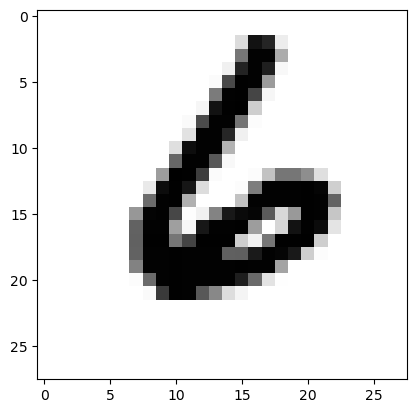

In [8]:
# Plot the Image
image_index = 8888
plt.imshow(x_test[image_index].reshape(28,28), cmap='Greys')

In [9]:
# Make Prediction
pred = lenet.predict(x_test[image_index].reshape(1, rows, cols, 1 ))
print(pred.argmax())

1/1 [==============================] - 0s 273ms/step
6


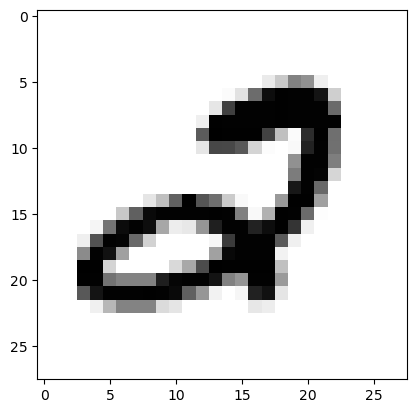

In [10]:
# Plot the Image
image_index = 8889
plt.imshow(x_test[image_index].reshape(28,28), cmap='Greys')

In [11]:
# Make Prediction
pred = lenet.predict(x_test[image_index].reshape(1, rows, cols, 1 ))
print(pred.argmax())

1/1 [==============================] - 0s 32ms/step
2


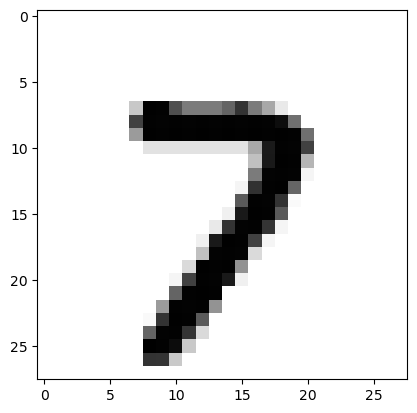

In [13]:
# Plot the Image
image_index = 8891
plt.imshow(x_test[image_index].reshape(28,28), cmap='Greys')

In [14]:
# Make Prediction
pred = lenet.predict(x_test[image_index].reshape(1, rows, cols, 1 ))
print(pred.argmax())

1/1 [==============================] - 0s 33ms/step
7
